# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'   # [정답안] 예시 번호
if not student_id or not student_id.isascii() or not student_id.isdigit():  # 비어 있거나, 영숫자 외 문자가 있거나, 숫자가 아니면 오류
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')  # 수험번호 형식 오류를 알리고 실행을 멈춤
print('수험번호:', student_id)  # 입력한 수험번호를 화면에 출력

수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 1-2. 

> 내가 일하고 있는 공공기관 B는 전 세계적으로 유명한 도서관, 박물관 등을 운영하는 기관이다. \
> 최근 이용자들이 많아져, 시설 이용객들의 연령을 기반으로 맞춤형 프로그램과 편의시설, 안내 서비스 등으로 운영을 개선하자는 프로젝트가 시작되었다.\
> 모든 이용객들의 연령 정보를 직접 물어보고 수집하는 것은 현실적으로 어렵고 큰 비효율이 발생하는 문제가 존재한다.\
> 나는 시설에 합법적으로 취득된 전 세계의 사람들의 얼굴 사진을 수집 및 분석하여 이용자들의 연령대를 자동으로 예측하는 AI 활용을 건의하였다. \
> 내 제안에 대해서 기관장의 전폭적인 지지로, 얼굴 사진 데이터셋을 확보 할 수 있었고, 얼굴 기반의 연령 예측 모델 개발을 책임지게 되었다. 


기관 B가 제공한 학습 `train` 및 평가 `val` 데이터를 기반으로 최적의 **얼굴 이미지 기반 나이 예측 모델**을 설계해야 합니다.



## 공통 조건

공공기관 B가 사용 및 수집할 수 있는 자원은 한정되어 있으며, 이에 따라 사전에 사용할 기반 모델과 사진의 크기는 다음과 같은 제약조건이 부여되었습니다.

- 모델은 TinyViT 5M `dist_in22k_ft_in1k`만 사용합니다. 다른 모델이나 외부 데이터는 사용할 수 없습니다.
- 입력은 제공된 **112 × 112 RGB** 크기로 유지합니다.
- 모델은 처음부터 **Full Fine-Tuning**으로 학습합니다.
  - 모델 구조와 학습 epoch 수(25)는 고정합니다. (수정 불가)
- 제공된 train / val 구분과 구성 및 정답은 변경하지 마세요.
  - 모든 학습 데이터 `train` 을 사용해야 합니다.
  - `val`은 검증 (validation) 용도입니다.

## 평가 지표

공공기관 B는 일정한 오차 범위 내에서 이용객의 나이를 예측하는 모델을 요청하였습니다. 이에 따라 평가 지표는 `CS@10`을 사용해야 합니다.
* `CS@k`는 전체 이미지 중 **예측 나이와 실제 나이의 차이가 k세 이하인 이미지의 비율**입니다.
  * 값이 높을수록 좋습니다.

#### 사용할 평가 지표: CS@10 (Cumulative Score at 10)

* 예측 오차가 **10세 이하**인 이미지의 비율입니다.

$$
\mathrm{CS@10}
=
\frac{\text{예측 나이와 실제 나이의 차이가 10세 이하인 이미지 수}}
{\text{전체 평가 이미지 수}}
\times 100 \; (\%)
$$

* 예를 들어, 평가 이미지 100장 중 60장의 예측 오차가 10세 이하라면 **CS@10 = 60%**입니다.
* 예측 나이는 반올림하지 않고 계산하며, 오차가 정확히 5세 또는 10세인 경우도 각각 포함합니다.

## 현실 적용에서의 고려 사항 (힌트)
공공기관 B에서 관할하는 실제 이용시설의 종류와 내부에 설치된 카메라의 위치는 다양합니다. \
실제 환경에서는 이용객들의 정면 사진을 취득하는 것은 현실적이지 않습니다. \
따라서, **기관 B는 현실적인 데이터 상황으로 고려하여, 평가 `val`과 테스트 `test` 데이터셋을 구성하였을 가능성이 있습니다.**

다만, 학습을 위해 급하게 비용을 지불하고 확보된 **학습 `train` 데이터셋에서는 고품질로 정돈된 곧바른 형태의 정면 얼굴 사진과 정답 나이 라벨을 제공해주었습니다.**

## 시험 환경 및 실습 가이드라인

* 환경과 데이터는 이미 준비되어 있습니다. 이 폴더의 `.venv\Scripts\python.exe`를 노트북 커널로 선택하고, 준비된 `data/utkface/`를 사용하여 위에서부터 실행하세요.
* P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다.

* `### Write Your Code Here ###`는 작성하거나 수정할 부분입니다. 제공 코드를 그대로 실행해 개선 전 성능을 확인할 수 있습니다.


> ## [예시 정답안]
> 진단 = **train(정면) ↔ val/test(카메라 사진) 분포 차이** + 제공 증강이 너무 셈 → val에서 본 범위만큼만 증강. 바뀐 셀: 증강 셀, 확인용 그림 셀.

참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정

환경과 데이터는 이미 준비되어 있습니다. 아래 셀에서 이 폴더의 `.venv`와 GPU가 확인되어야 합니다.\
VS Code 또는 PyCharm의 노트북 커널은 `.venv\Scripts\python.exe`로 선택하세요.


In [2]:
# [정답안] 환경 확인 - CPU/GPU 겸용 (원본은 GPU가 없으면 여기서 멈춥니다)
import sys  # 파이썬 인터프리터 정보(sys.prefix, sys.executable)를 쓰기 위한 모듈
from pathlib import Path  # 경로를 객체로 다루는 Path 클래스

print('Python:', sys.version.split()[0])  # 현재 파이썬 버전 출력 (예: 3.12.10)
print('현재 커널:', sys.executable)  # 지금 노트북을 실행 중인 python.exe 경로 출력 → .venv인지 확인
print('작업 폴더:', Path.cwd())  # 현재 작업 폴더 출력 (상대 경로 data/... 의 기준)

expected_env = Path.cwd() / '.venv'  # 작업 폴더 아래 .venv 폴더 경로를 기대값으로 만듦
if Path(sys.prefix).resolve() != expected_env.resolve():  # 실행 중인 파이썬의 환경 폴더가 기대한 .venv와 다르면
    raise RuntimeError(  # 잘못된 커널이라는 오류를 발생
        f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요. "  # 선택해야 할 python.exe 경로를 안내 문구에 넣음
        '환경이 없다면 setup.cmd를 실행하고, 작업 폴더도 노트북이 있는 폴더로 맞추세요.'  # 안내 문구 두 번째 줄 (setup.cmd 실행 안내)
    )

import torch  # PyTorch: 텐서 연산·자동 미분·신경망
import torchvision  # torchvision: 이미지 변환(transforms)
import timm  # timm: 사전학습 이미지 모델 라이브러리 (P1_1에서 모델 생성에 사용)
print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)  # 설치된 세 라이브러리 버전 출력

if torch.cuda.is_available():  # CUDA GPU를 쓸 수 있으면
    DEVICE, QUICK = 'cuda', False  # 장치는 GPU, QUICK(축소 실행) 모드는 끔
    print('GPU:', torch.cuda.get_device_name(0), '-> 원본 설정 그대로 실행합니다.')  # GPU 이름 출력
else:  # 그렇지 않으면 (아래 실행)
    DEVICE, QUICK = 'cpu', True  # 장치는 CPU, QUICK 모드 켬 → 뒤의 [정답안 전용] 셀이 데이터·epoch를 줄임
    print('GPU 없음 -> QUICK 모드: 학습 데이터와 epoch를 줄여 CPU에서 끝까지 실행합니다.')  # CPU 실행 안내
    print('           점수는 시험 기준보다 낮게 나옵니다. 코드 흐름 확인용입니다.')  # 점수가 낮게 나오는 이유 안내

Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
GPU: NVIDIA GeForce RTX 5060 Ti -> 원본 설정 그대로 실행합니다.


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# 수정 금지

from pathlib import Path  # 경로를 객체로 다루는 Path 클래스
import csv  # CSV 읽기·쓰기
import time  # 학습 시간 측정용

import numpy as np  # NumPy: 이미지 배열(N, H, W, 3) 처리
import matplotlib.pyplot as plt  # 그래프 그리기
from PIL import Image  # 이미지 파일 열기 (Pillow)
from tqdm.auto import tqdm  # 진행 막대
import torch  # PyTorch: 텐서 연산·자동 미분·신경망
from torch import nn  # nn: 신경망 층(Linear, Conv2d 등)과 Loss 클래스
from torch.nn import functional as F  # F: 함수형 API (interpolate, log_softmax, pad 등)
from torch.utils.data import Dataset, DataLoader  # Dataset(데이터 한 개 꺼내기 규칙), DataLoader(배치로 묶기)
from torchvision import transforms as T  # 이미지 변환 모음을 T라는 이름으로 사용 (V1 API)
from torchvision.transforms import InterpolationMode  # 보간 방식 이름 (BILINEAR 등)
import random  # 파이썬 기본 난수 (시드 고정용)

device = 'cuda' if torch.cuda.is_available() else 'cpu'  # GPU가 있으면 'cuda', 없으면 'cpu'를 장치로 사용
print('사용 장치:', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU')  # 사용 장치 이름 출력

SEED = 42  # 시드 값
random.seed(SEED)  # random 시드
np.random.seed(SEED)  # NumPy 시드
torch.manual_seed(SEED)  # PyTorch CPU 시드
torch.cuda.manual_seed_all(SEED)  # PyTorch GPU 시드


사용 장치: NVIDIA GeForce RTX 5060 Ti


## 데이터 준비

이미 준비된 `data/utkface/` 데이터를 그대로 사용합니다. 

```text
data/utkface/
├── train.csv
├── val.csv
├── train/
└── val/
```

- `train.csv`, `val.csv`: UTF-8 형식이며 `filename,label` 두 열이 있습니다.
- `filename`: 데이터셋 폴더 기준 이미지 상대 경로입니다. 예: `train/000000.png`
- `label`: 정답 나이입니다. 
- 이미지는 RGB, 가로 112 × 세로 112입니다.
- `train`은 학습, `val`은 검증용입니다. 제공된 구분과 정답은 변경하지 마세요. (test 셋은 공개되지 않습니다)


In [4]:
# 수정 금지

data_dir = Path('data/utkface')  # UTKFace 데이터 폴더
if not (data_dir / 'train.csv').is_file() or not (data_dir / 'val.csv').is_file():  # train.csv나 val.csv가 없으면
    raise FileNotFoundError('먼저 setup.cmd를 실행하고, 작업 폴더를 노트북이 있는 폴더로 맞추세요.')  # 데이터 준비 오류
output_dir = Path('outputs')  # 결과 저장 폴더
output_dir.mkdir(exist_ok=True)  # 폴더가 없으면 만듦 (있으면 그대로)


In [5]:
# 수정 금지

def read_rows(split):  # CSV를 {파일명, 나이} 목록으로 읽는 함수
    with (data_dir / f'{split}.csv').open(encoding='utf-8', newline='') as file:  # train.csv / val.csv 열기
        return [  # 리스트 만들기 시작
            {'filename': row['filename'], 'label': float(row['label'])}  # 파일명 문자열과 나이(실수)
            for row in csv.DictReader(file)  # CSV 각 행을 사전으로 읽음
        ]

train_rows = read_rows('train')  # 학습 목록
val_rows = read_rows('val')  # 검증 목록
print('학습:', len(train_rows), '검증:', len(val_rows))  # 개수 출력
print('첫 번째 항목:', train_rows[0])  # 첫 항목 확인


학습: 6000 검증: 1500
첫 번째 항목: {'filename': 'train/000000.png', 'label': 35.0}


> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [6]:
# [정답안 전용] CPU QUICK 모드에서만 학습/검증 데이터를 줄입니다.
if QUICK:  # CPU(QUICK) 모드일 때만
    train_rows = train_rows[:1500]  # QUICK: 학습 1,500장만
    val_rows = val_rows[:500]  # QUICK: 검증 500장만
    print('QUICK 모드 데이터:', len(train_rows), len(val_rows))  # 줄인 개수 출력

In [7]:
# 수정 금지

mean = (0.485, 0.456, 0.406)  # ImageNet 채널별 평균 (사전학습 때 쓴 값)
std = (0.229, 0.224, 0.225)  # ImageNet 채널별 표준편차
fill = (124, 116, 104)  # 빈 곳을 채울 색 (평균에 가까운 회갈색)
eval_transform = T.Compose([  # 평가용 변환: 증강 없이 텐서 변환 + 정규화만
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])


In [8]:
# 수정 금지

class UTKFaceDataset(Dataset):  # CSV 목록으로 얼굴 이미지를 읽는 Dataset
    def __init__(self, rows, transform):  # 생성자
        self.rows = list(rows)  # 목록 복사 저장
        self.transform = transform  # 적용할 변환 저장

    def __len__(self):  # 데이터 개수를 알려주는 함수 (DataLoader가 사용)
        return len(self.rows)  # 데이터 개수

    def __getitem__(self, index):  # index번째 샘플을 꺼내는 함수
        row = self.rows[index]  # index번째 행
        with Image.open(data_dir / row['filename']) as image:  # 이미지 파일 열기
            image = self.transform(image.convert('RGB'))  # RGB로 바꾼 뒤 변환 적용
        return image, torch.tensor(row['label'], dtype=torch.float32)  # (이미지 텐서, 나이 실수 텐서) 반환


## 학습데이터 전처리 단계
아래 코드에는 학습데이터 증강을 위한 `train_transform` 이 작성되어 있습니다.\
필요한 변환을 추가. 삭제, 그리고 조정하여 평가 시 얼굴의 나이를 효과적으로 유추할 수 있도록 학습데이터를 증강할 수 있습니다.

### 수정 가능 범위
* 주어진 변환 범위·확률·순서를 바꾸거나 변환을 추가·제거할 수 있습니다.
* 이미지의 입력 크기, 텐서 변환과 정규화는 변경하지 마세요.
* 데이터 선택·복제, 모델, epoch 수(25)와 평가 코드는 변경하지 마세요.

### 주의!
* 전처리를 변경하면 Dataset/DataLoader 셀도 다시 실행하세요.
* 매 실험은 제공된 사전학습 가중치로부터 모델 학습이 진행되어야 합니다.

### 공식 문서
- [torchvision Transform 전처리 요소 설명](docs/pages/docs.pytorch.org/vision_main_transforms--7c151205d9a0.html)
  - 유의점: 공식문서에서는 torchvision을 v2 명칭으로 import했지만, 본 노트북에서는 T로 import했습니다. 

이 노트북은 `torchvision.transforms`를 전처리 과정에서 사용합니다.

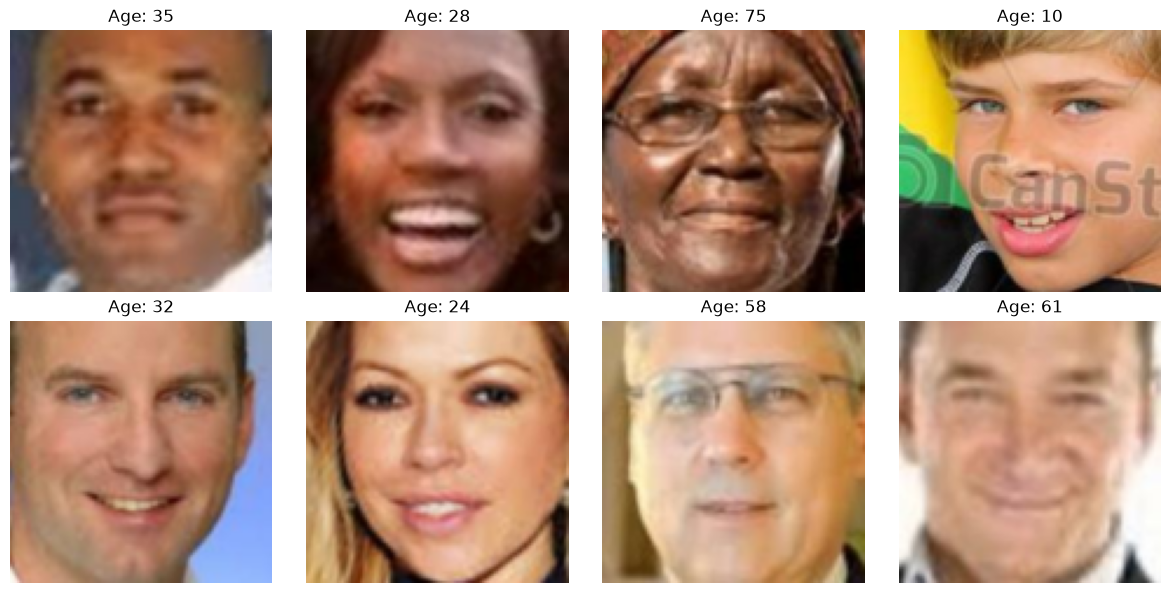

In [9]:
# 수정 금지

fig, axes = plt.subplots(2, 4, figsize=(12, 6))  # 2×4 격자 그림
for axis in axes.flat:  # 모든 칸에 대해
    axis.axis('off')  # 축 눈금·테두리 숨김
for axis, row in zip(axes.flat, train_rows[:8]):  # 앞 8개 학습 이미지를 칸에 배치
    with Image.open(data_dir / row['filename']) as image:  # 이미지 파일 열기
        axis.imshow(image.convert('RGB'))  # RGB 이미지 표시
    axis.set_title(f"Age: {row['label']:g}")  # 제목에 나이
plt.tight_layout()  # 여백 자동 정리
plt.show()  # 그림 표시


# **답안 작성 셀 - 전처리**

### 주의!
* 전처리를 변경하면 Dataset/DataLoader 셀도 다시 실행하세요.
* 매 실험은 제공된 사전학습 가중치로부터 모델 학습이 진행되어야 합니다.


In [10]:
# 수정 가능
# 변환을 추가, 삭제, 조절할 수 있습니다.

# [정답안] train은 '곧바른 정면', val/test는 설치 카메라 사진(기울어짐·위치 이동·확대·밝기 차이).
# -> train을 val/test처럼 보이게 만드는 증강을 적당한 세기로 넣습니다.
#    제공 값(shift 0.80, shear 50도, 지우기 95%)은 얼굴이 화면 밖으로 나가거나 심하게 찌그러져
#    나이 단서(주름, 피부, 얼굴형)가 사라지므로 크게 줄입니다.
shift = 0.12            # 위치 이동: 이미지 크기의 ±12%
shear = (-8.0, 8.0)     # 비스듬한 각도: 약하게
tilt = 30.0             # 카메라 기울기: ±30도 (val에서 확인한 범위)
mask_probability = 0.25 # 일부 가림(안경, 손 등)은 가끔만
mask_area = (0.02, 0.08)  # 가리는 영역 크기: 이미지 면적의 2~8%

train_transform = T.Compose([  # 학습용 변환을 차례로 묶음
    T.RandomHorizontalFlip(p=0.5),  # 50% 확률로 좌우 반전 (상품 종류는 그대로)
    T.RandomAffine(degrees=0, translate=(shift, shift), scale=(1.0, 1.25),  # 이동 ±12%, 확대 1.0~1.25배 (val의 확대된 얼굴 대응)
                   interpolation=InterpolationMode.BILINEAR, fill=fill),  # 이중선형 보간, 빈 곳은 fill 색
    T.RandomAffine(degrees=0, shear=shear,  # 비스듬히 기울이기(shear) ±8° (약하게)
                   interpolation=InterpolationMode.BILINEAR, fill=fill),  # 이중선형 보간, 빈 곳은 fill 색
    T.RandomRotation(degrees=tilt, interpolation=InterpolationMode.BILINEAR,  # ±30° 회전 (설치 카메라 기울기)
                     expand=False, fill=fill),  # 이미지 크기 유지, 빈 곳 fill 색
    T.ColorJitter(brightness=0.3, contrast=0.2),  # 밝기 ±30%, 대비 ±20%
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.RandomErasing(p=mask_probability, scale=mask_area,  # 25% 확률로 작은 직사각형을 가림 (안경·손 등 가림 대응)
                    ratio=(0.5, 2.0), value=mean),  # 가로세로 비율 0.5~2, 가린 곳은 평균색 (정규화 후 0)
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])

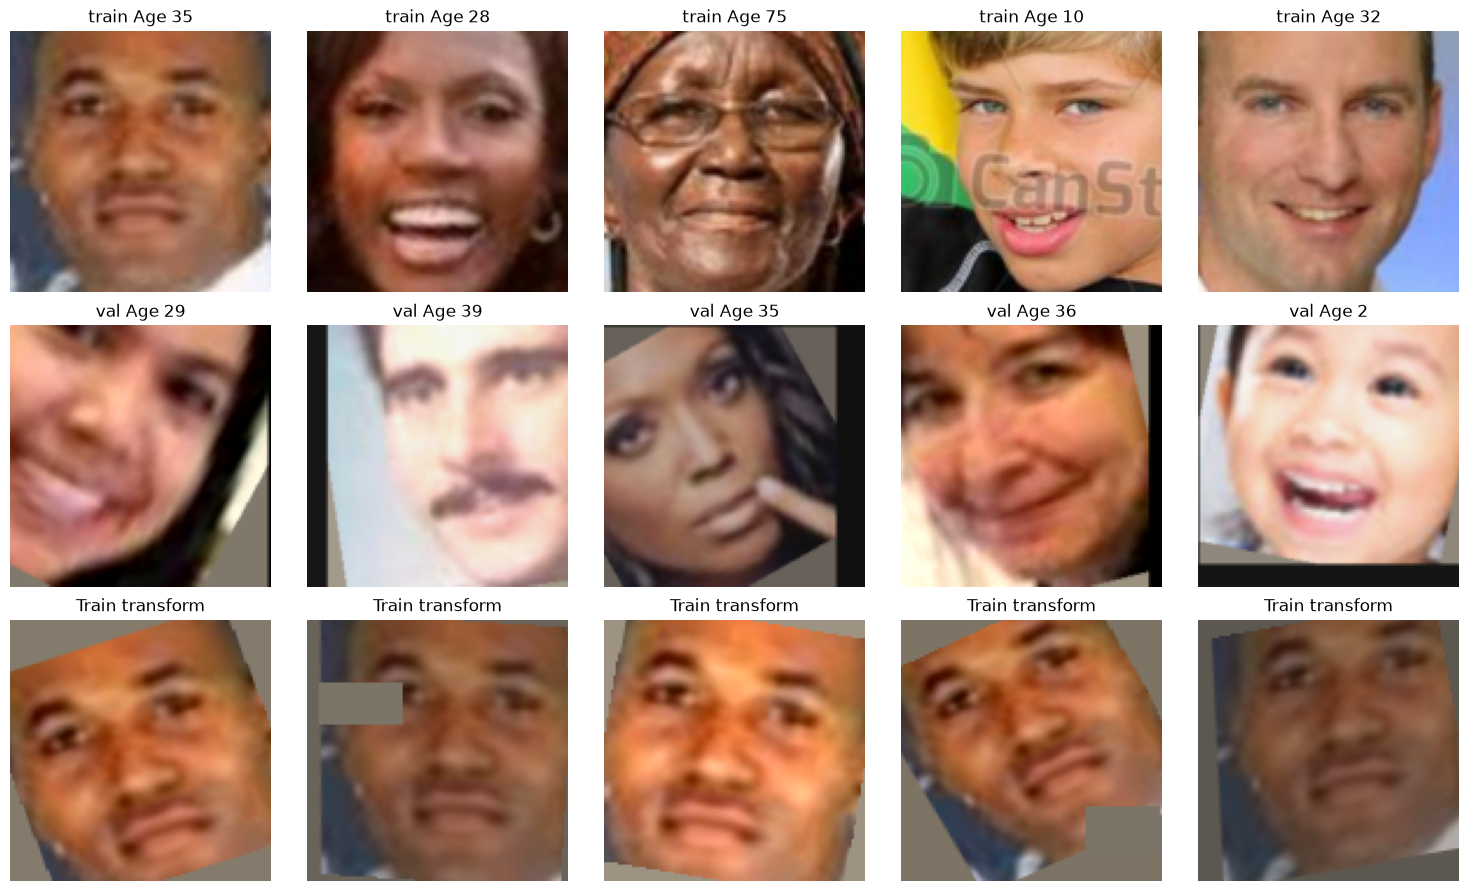

In [11]:
# 수정 가능
# 이미지 확인용 코드입니다. 일부를 수정하여 evaluation 데이터를 확인할 수도 있습니다.

# [정답안] train(위)과 val(아래)을 나란히 보고 '분포 차이'를 직접 확인합니다.
fig, axes = plt.subplots(3, 5, figsize=(15, 9))  # 3×5 격자 그림
for axis, row in zip(axes[0], train_rows[:5]):  # 첫 줄: 학습 이미지 5장
    with Image.open(data_dir / row['filename']) as image:  # 이미지 파일 열기
        axis.imshow(image.convert('RGB'))  # RGB 이미지 표시
    axis.set_title(f"train Age {row['label']:g}")  # 제목: train 나이
for axis, row in zip(axes[1], val_rows[:5]):  # 둘째 줄: 검증 이미지 5장
    with Image.open(data_dir / row['filename']) as image:  # 이미지 파일 열기
        axis.imshow(image.convert('RGB'))  # RGB 이미지 표시
    axis.set_title(f"val Age {row['label']:g}")  # 제목: val 나이
with Image.open(data_dir / train_rows[0]['filename']) as image:  # 첫 학습 이미지 열기
    sample_image = image.convert('RGB')  # RGB 복사본 저장
for axis in axes[2]:  # 셋째 줄 칸마다
    tensor = train_transform(sample_image)  # 같은 이미지에 학습 변환 적용 (매번 다르게 나옴)
    restored = tensor * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]  # 정규화를 되돌려 0~1 범위로 복원
    axis.imshow(restored.permute(1, 2, 0).clamp(0, 1))  # (C,H,W) → (H,W,C)로 바꾸고 0~1로 잘라 표시
    axis.set_title('Train transform')  # 제목
for axis in axes.flat:  # 모든 칸에 대해
    axis.axis('off')  # 축 눈금·테두리 숨김
plt.tight_layout()  # 여백 자동 정리
plt.show()  # 그림 표시

### [정답안 해설]
- **문제의 핵심은 '데이터 분포 차이'** 입니다. 힌트에 train은 *정돈된 정면 사진*, val/test는 *현실 카메라 위치*라고 했습니다. 위 그림의 val 줄을 보면 기울어지고, 옮겨지고, 확대되고, 밝기가 다릅니다.
- 그래서 증강은 **val에서 본 변화만, 비슷한 크기로** 넣습니다: 회전 ±30°, 이동 ±12%, 확대 1.0~1.25배, 좌우 반전, 밝기·대비.
- 제공된 기본값은 **과한 증강**입니다(이동 80%면 얼굴이 화면 밖으로 나가고, shear 50°는 얼굴형을 망가뜨리고, 95% 확률로 가림). 나이 단서가 사라져 성능이 떨어집니다. → *부적절한 데이터 증강* 항목에 해당합니다.
- 빈 곳을 채우는 색 `fill=(124,116,104)`는 제공 값 그대로 씁니다(평균 색이라 정규화 후 0에 가까움).
- 고정: 입력 크기 112, ToTensor/Normalize, 모델, 25 epoch, `SmoothL1Loss(beta=5.0)`.

## 제공 모델: TinyViT 5M
### 아래 **모델 구조에 관한 코드는 수정하지 마세요.**

* 아래에는 TinyViT 5M의 구성 블록이 직접 구현되어 있습니다.
* 이 문제에서는 전체 모델을 학습하는 방식을 활용합니다.
  * Full fine-tuning


#### 입력을 특징 맵으로 바꾸기

* 입력 사이즈는 `(B, 3, 112, 112)` 여야 합니다.
* 기본값으로 코드에 구현되어 있습니다.


In [12]:
# 수정 금지

class ConvNorm(nn.Sequential):  # Conv2d + BatchNorm2d 묶음 (nn.Sequential을 상속)
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""  # 클래스 설명(docstring)
    def __init__(self, in_channels, out_channels, kernel_size=1,  # 입력 채널, 출력 채널, 커널 크기
                 stride=1, padding=0, groups=1, bn_weight=1.0):  # stride, padding, 그룹 수(depthwise면 채널 수), BN 초기 가중치
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv = nn.Conv2d(  # 합성곱 층
            in_channels, out_channels, kernel_size,  # 채널·커널
            stride=stride, padding=padding, groups=groups, bias=False,  # bias는 BN이 대신하므로 False
        )
        self.bn = nn.BatchNorm2d(out_channels)  # 배치 정규화 층
        nn.init.constant_(self.bn.weight, bn_weight)  # BN 스케일 초기값
        nn.init.zeros_(self.bn.bias)  # BN 이동값 0으로 초기화


class PatchEmbed(nn.Module):  # 입력 이미지를 특징 맵으로 바꾸는 첫 블록
    """원본 입력을 특징 맵으로 변환: [B, 3, 112, 112] → [B, 64, 28, 28]."""  # 클래스 설명(docstring)
    def __init__(self, dim=64):  # dim=64: 출력 채널 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)  # 3→32채널, stride 2 (해상도 1/2)
        self.act = nn.GELU()  # GELU 활성화
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)  # 32→64채널, stride 2 (해상도 1/4)

    def forward(self, x):  # 순전파 정의
        x = self.conv1(x)  # 첫 합성곱
        x = self.act(x)  # 활성화
        return self.conv2(x)  # 두 번째 합성곱 결과 반환


#### 합성곱 블록과 해상도 축소

첫 stage는 MBConv를 사용합니다. 이후 stage는 Patch Merging으로 해상도를 줄입니다.


In [13]:
# 수정 금지

class MBConv(nn.Module):  # MobileNet식 역병목 합성곱 블록 (stage 0)
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""  # 클래스 설명(docstring)
    def __init__(self, dim, expand_ratio=4):  # expand_ratio=4: 중간 채널을 4배로 늘림
        super().__init__()  # nn.Module 초기화 (필수)
        hidden_dim = dim * expand_ratio  # 중간 채널 수
        self.conv1 = ConvNorm(dim, hidden_dim)  # 1×1 합성곱으로 채널 확장
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,  # 3×3 depthwise 합성곱 (채널별로 따로)
                              padding=1, groups=hidden_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)  # 1×1로 채널 축소 (BN 가중치 0 → 처음엔 항등 연결처럼 동작)
        self.act3 = nn.GELU()  # 활성화

    def forward(self, x):  # 순전파 정의
        shortcut = x  # 잔차 연결용 입력 저장
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        x = self.conv3(x)  # 축소
        return self.act3(x + shortcut)  # 입력을 더한 뒤(잔차) 활성화


class ConvStage(nn.Module):  # MBConv 여러 개를 쌓은 stage
    def __init__(self, dim, depth):  # 채널, 블록 개수
        super().__init__()  # nn.Module 초기화 (필수)
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])  # depth개의 MBConv를 순서대로 연결

    def forward(self, x):  # 순전파 정의
        return self.blocks(x)  # 블록들 통과


class PatchMerging(nn.Module):  # 해상도를 절반으로 줄이며 채널을 바꾸는 블록
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""  # 클래스 설명(docstring)
    def __init__(self, in_dim, out_dim):  # 입력·출력 채널
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(in_dim, out_dim)  # 1×1로 채널 변경
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,  # 3×3 depthwise, stride 2 (해상도 1/2)
                              padding=1, groups=out_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(out_dim, out_dim)  # 1×1 합성곱

    def forward(self, x):  # 순전파 정의
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        return self.conv3(x)  # 마지막 합성곱 결과 반환


#### Window Attention과 MLP

각 window 내부의 위치 관계를 상대 위치 bias로 표현합니다.


In [14]:
# 수정 금지

class NormMLP(nn.Module):  # LayerNorm → Linear → GELU → Linear 다층 퍼셉트론
    def __init__(self, dim, mlp_ratio=4):  # mlp_ratio=4: 중간 차원 4배
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)  # 차원 확장
        self.act = nn.GELU()  # GELU 활성화
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)  # 차원 복원

    def forward(self, x):  # 순전파 정의
        x = self.norm(x)  # 정규화
        x = self.fc1(x)  # 확장
        x = self.act(x)  # 활성화
        return self.fc2(x)  # 복원 결과 반환


class WindowAttention(nn.Module):  # window 안에서만 하는 multi-head self-attention
    """작은 window 안에서 수행하는 multi-head self-attention."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.num_heads = num_heads  # head 수 저장
        self.head_dim = dim // num_heads  # head 하나의 차원
        self.scale = self.head_dim ** -0.5  # 점수 스케일 1/√(head 차원)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.qkv = nn.Linear(dim, dim * 3)  # Q, K, V를 한 번에 만드는 Linear (출력 3배)
        self.proj = nn.Linear(dim, dim)  # head를 합친 뒤 출력 투영

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(  # window 안 모든 위치의 (행, 열) 좌표
            torch.arange(window_size), torch.arange(window_size), indexing="ij"  # 0..window-1 격자
        )).flatten(1)  # (2, window²) 모양으로 펼침
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()  # 모든 위치 쌍의 행·열 거리 (절댓값)
        bias_indices = offsets[0] * window_size + offsets[1]  # 거리 (dy, dx)를 bias 표의 번호로 바꿈
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)  # 번호표를 버퍼로 저장 (학습 안 함, state_dict에도 안 넣음)
        self.attention_biases = nn.Parameter(  # 거리별 학습 가능한 bias 표
            torch.zeros(num_heads, window_size * window_size)  # (head 수, window²) 크기, 0으로 시작
        )

    def forward(self, x):  # 순전파 정의
        batch_size, num_tokens, dim = x.shape  # (window 개수×배치, 토큰 수, 차원)
        x = self.norm(x)  # 정규화

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(  # QKV 계산 후 모양 변경
            batch_size, num_tokens, self.num_heads, 3, self.head_dim  # (B, N, head, [q|k|v], head 차원)
        )
        qkv = qkv.permute(3, 0, 2, 1, 4)  # (3, B, head, N, head 차원)으로 순서 변경
        q, k, v = qkv.unbind(dim=0)  # q, k, v로 분리

        attention = (q * self.scale) @ k.transpose(-2, -1)  # 스케일된 Q·Kᵀ = 위치 쌍별 유사도 (B, head, N, N)
        bias = self.attention_biases[:, self.attention_bias_idxs]  # 각 위치 쌍의 거리에 해당하는 bias를 꺼냄
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)  # bias를 더하고 softmax → 주의 가중치
        x = attention @ v  # 가중치로 V를 섞음
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)  # head들을 다시 이어붙여 (B, N, 차원)
        return self.proj(x)  # 출력 투영 결과 반환


#### Attention 블록과 Stage

특징 맵을 window로 나누고, 필요한 padding은 attention 후 제거합니다. 각 stage의 출력 크기는 28 × 28, 14 × 14, 7 × 7, 4 × 4입니다.


In [15]:
# 수정 금지

class TinyViTBlock(nn.Module):  # attention + local conv + MLP 블록
    """Window attention → local convolution → MLP."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.window_size = window_size  # window 크기 저장
        self.attn = WindowAttention(dim, num_heads, window_size)  # window attention 층
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)  # 3×3 depthwise 합성곱 (가까운 위치 정보 섞기)
        self.mlp = NormMLP(dim)  # MLP 층

    def forward(self, x):  # 순전파 정의
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape  # (B, H, W, C) 모양 분해
        shortcut = x  # 잔차 연결용 입력 저장
        window = self.window_size  # window 크기

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window  # 높이를 window 배수로 맞출 아래쪽 padding
        pad_w = (window - width % window) % window  # 너비를 window 배수로 맞출 오른쪽 padding
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))  # (채널, 너비, 높이) 순서로 0 padding
        padded_h, padded_w = height + pad_h, width + pad_w  # padding 후 크기
        num_h, num_w = padded_h // window, padded_w // window  # 세로·가로 window 개수

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)  # window 단위로 나눔
        x = x.transpose(2, 3).reshape(-1, window * window, channels)  # (B×window 개수, window², C) 토큰 묶음으로
        x = self.attn(x)  # window마다 attention

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)  # 다시 window 격자 모양으로
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)  # 이미지 모양 (B, H', W', C)로 복원
        x = x[:, :height, :width, :].contiguous()  # padding 부분 잘라냄
        x = shortcut + x  # 잔차 연결

        x = x.permute(0, 3, 1, 2)  # (B, C, H, W)로 바꿈 (합성곱 입력 형식)
        x = self.local_conv(x)  # local 합성곱
        x = x.flatten(2).transpose(1, 2)  # (B, H×W, C) 토큰 형식으로
        x = x + self.mlp(x)  # MLP + 잔차 연결
        return x.reshape(batch_size, height, width, channels)  # (B, H, W, C)로 되돌려 반환


class TinyViTStage(nn.Module):  # PatchMerging + TinyViTBlock 여러 개
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):  # 입력·출력 채널, 블록 수, head 수, window 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.downsample = PatchMerging(in_dim, out_dim)  # 해상도 절반 + 채널 변경
        self.blocks = nn.Sequential(*[  # 블록들을 순서대로 연결
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)  # depth개의 attention 블록
        ])

    def forward(self, x):  # 순전파 정의
        x = self.downsample(x)  # 해상도 줄이기 (B, C, H, W)
        x = x.permute(0, 2, 3, 1)  # (B, H, W, C)로 바꿈 (블록 입력 형식)
        x = self.blocks(x)  # 블록들 통과
        return x.permute(0, 3, 1, 2)  # (B, C, H, W)로 되돌려 반환


#### 사전학습 가중치 불러오기

원래 1,000개 클래스의 가중치를 `strict=True`로 불러온 뒤 출력층을 나이 예측용 1개 출력으로 교체합니다. \
작은 window에 맞춰 상대 위치 bias만 보간하며 나머지 가중치는 그대로 사용합니다. 이 로딩 코드는 변경하지 마세요.


In [16]:
# 수정 금지
# 사전학습 가중치 로딩과 출력 head입니다.

from safetensors.torch import load_file  # safetensors 형식 가중치 파일을 읽는 함수


class ClassifierHead(nn.Module):  # 평균 풀링 → LayerNorm → Linear 분류 head
    def __init__(self, dim, num_classes):  # 입력 차원, 클래스 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim, eps=1e-5)  # 정규화 층
        self.fc = nn.Linear(dim, num_classes)  # 분류층

    def forward(self, x):  # 순전파 정의
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.norm(x)  # 정규화
        return self.fc(x)  # 클래스 점수 반환


def load_pretrained_weights(model):  # 로컬 사전학습 가중치를 모델에 넣는 함수
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""  # 함수 설명(docstring)
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')  # 노트북 옆에 있어야 할 가중치 파일
    if not path.is_file():  # 파일이 없으면
        raise FileNotFoundError(  # 오류 발생
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'  # 찾은 절대 경로를 오류 문구에 넣음
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'  # 오류 안내 두 번째 줄
        )
    weights = load_file(str(path))  # 가중치를 {이름: 텐서} 사전으로 읽음
    target = model.state_dict()  # 현재 모델의 {이름: 텐서} (모양 비교용)
    for name, value in weights.items():  # 가중치를 하나씩 돌며
        if name.endswith('attention_biases') and value.shape != target[name].shape:  # attention 상대 위치 bias인데 모양이 다르면 (window 크기를 줄였기 때문)
            num_heads, length = value.shape  # (head 수, window²) 모양 분해
            old_window = int(length ** 0.5)  # 원래 window 한 변 길이 (예: 49 → 7)
            new_window = int(target[name].shape[1] ** 0.5)  # 새 window 한 변 길이 (예: 9 → 3)
            weights[name] = F.interpolate(  # bias를 2차원 격자로 보고 크기를 줄임
                value.float().reshape(1, num_heads, old_window, old_window),  # (1, head, 원래 window, 원래 window) 이미지처럼 바꿈
                size=(new_window, new_window),  # 목표 크기
                mode='bicubic', antialias=True,  # bicubic 보간 + antialias (부드럽게 축소)
            ).reshape(num_heads, new_window * new_window)  # 다시 (head, 새 window²) 모양으로
    model.load_state_dict(weights, strict=True)  # strict=True: 모든 이름·모양이 정확히 맞아야 로딩 (빠진 것 있으면 오류)


In [17]:
# 수정 금지
# 고정 모델입니다.

class UTKFaceModel(nn.Module):  # 나이 회귀용 TinyViT 5M
    """사전학습 체크포인트와 호환되는 TinyViT 5M입니다."""  # 클래스 설명(docstring)
    def __init__(self):  # 생성자
        super().__init__()  # nn.Module 초기화 (필수)
        self.patch_embed = PatchEmbed(dim=64)  # 입력 → 64채널 특징 맵
        self.stages = nn.Sequential(  # 4개 stage 묶음
            ConvStage(dim=64, depth=2),  # stage 0: MBConv 2개 (64채널)
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),  # stage 1: 128채널, 블록 2, head 4, window 3
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),  # stage 2: 160채널, 블록 6, head 5, window 5
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),  # stage 3: 320채널, 블록 2, head 10, window 3
        )
        self.head = ClassifierHead(320, num_classes=1000)  # 원래 1000종 head (가중치 로딩을 위해 같은 모양으로 만듦)
        load_pretrained_weights(self)  # 사전학습 가중치 로딩 (strict)
        self.head.fc = nn.Linear(320, 1)  # 출력 1개(나이)로 교체

    def forward(self, x):  # 순전파 정의
        x = self.patch_embed(x)  # 특징 맵 만들기
        x = self.stages[0](x)  # stage 0
        x = self.stages[1](x)  # stage 1
        x = self.stages[2](x)  # stage 2
        x = self.stages[3](x)  # stage 3
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.head.norm(x)  # LayerNorm
        return self.head.fc(x)  # 최종 출력


## 제공 학습·평가 코드

* 각 epoch의 학습 Loss와 `val CS@10`을 기록하고 `val CS@10`이 가장 높은 모델을 저장합니다.
* 검증에서는 텐서 변환과 정규화만 적용하며 역전파를 수행하지 않습니다.
* 예측 나이는 반올림하거나 범위를 잘라내지 않고 평가합니다.
* `criterion`은 고정되어 있습니다. 수정할 수 없습니다.


In [18]:
# 수정 금지

def age_metrics(y_true, y_pred):  # 나이 지표 계산 함수
    error = np.asarray(y_pred, dtype=np.float64) - np.asarray(y_true, dtype=np.float64)  # 예측 - 정답 (64비트 실수)
    return {  # 사전 반환
        "cs10": float((np.abs(error) <= 10).mean() * 100),  # 오차 10세 이하 비율 × 100 = CS@10(%)
    }


def train_one_epoch(model, loader, criterion, optimizer):  # 나이 학습 1 epoch
    model.train()  # 학습 모드 (Dropout·BN이 학습 동작)
    total_loss, within_ten, count = 0.0, 0, 0  # Loss 합, 10세 이내 개수, 샘플 수
    progress = tqdm(loader, desc="Train", leave=False)  # 진행 막대가 붙은 반복자
    for images, ages in progress:  # 배치 반복
        images, ages = images.to(device), ages.to(device)  # 장치로 이동
        optimizer.zero_grad()  # gradient를 0으로 초기화 (다음 배치에 누적되지 않게)
        predictions = model(images).squeeze(1)  # (B,1) 출력을 (B,)로
        loss = criterion(predictions, ages)  # Loss 계산
        loss.backward()  # 역전파: 각 파라미터의 gradient 계산
        optimizer.step()  # gradient로 파라미터 갱신
        total_loss += loss.item() * len(ages)  # Loss 합계 누적
        within_ten += ((predictions.detach() - ages).abs() <= 10).sum().item()  # 오차 10세 이내 개수 누적 (detach: 그래프 분리)
        count += len(ages)  # 샘플 수 누적
        progress.set_postfix(loss=f"{total_loss / count:.3f}", cs10=f"{100 * within_ten / count:.2f}%")  # 진행 막대에 현재 Loss·CS@10 표시
    return total_loss / count, 100 * within_ten / count  # 평균 Loss와 학습 CS@10 반환


@torch.no_grad()  # 이 함수 전체를 gradient 없이 실행
def evaluate(model, loader, criterion):  # 검증 함수
    model.eval()  # 평가 모드 (Dropout 끔, BN은 저장된 통계 사용)
    total_loss = 0.0  # Loss 합
    y_true, y_pred = [], []  # 정답·예측 목록
    for images, ages in tqdm(loader, desc="Evaluate", leave=False):  # 진행 막대와 함께 배치 반복
        images, ages = images.to(device), ages.to(device)  # 장치로 이동
        predictions = model(images).squeeze(1)  # (B,1) 출력을 (B,)로
        total_loss += criterion(predictions, ages).item() * len(ages)  # Loss 합계 누적
        y_true.extend(ages.cpu().tolist())  # 정답 저장
        y_pred.extend(predictions.cpu().tolist())  # 예측 저장
    metrics = age_metrics(y_true, y_pred)  # CS@10 계산
    metrics["loss"] = total_loss / len(y_true)  # 평균 Loss 추가
    return metrics, np.asarray(y_true), np.asarray(y_pred)  # 지표, 정답 배열, 예측 배열 반환


### 고정된 학습 설정


In [19]:
# 수정 금지

EPOCHS = 25  # epoch 수 (고정)
batch_size = 64  # batch 크기: 한 번에 학습할 이미지 수
learning_rate = 1e-4  # 학습률 (고정)
weight_decay = 1e-4  # weight decay (고정)
checkpoint_path = output_dir / f'P1_2_{student_id}.pth'  # 체크포인트 파일
history_path = output_dir / f'P1_2_{student_id}_history.csv'  # 학습 기록 CSV 파일


> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [20]:
if QUICK:  # CPU(QUICK) 모드일 때만
    EPOCHS = 4  # QUICK: epoch 4로 줄임
    print('QUICK 모드 epoch:', EPOCHS)  # 줄인 epoch 출력

### `criterion`

* `criterion(predictions, targets)`는 `(B,)` 형태의 실수 예측 나이와 정답 나이를 입력받습니다.
* 반환값은 유한한 배치 평균 스칼라 텐서여야 하며, 예측에 대해 역전파가 가능해야 합니다.
* `criterion` 부분과 `Loss` 부분은 고정된 값입니다. 수정하지 마세요.


In [21]:
# 수정 금지

criterion = nn.SmoothL1Loss(beta=5.0)  # Smooth L1 Loss: 오차 5세까지는 제곱, 그 이상은 절댓값처럼 (고정)


In [22]:
# 수정 금지

train_dataset = UTKFaceDataset(train_rows, train_transform)  # 학습 Dataset (학습 변환)
val_dataset = UTKFaceDataset(val_rows, eval_transform)  # 검증 Dataset (평가 변환)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)  # 학습 DataLoader: 배치로 묶고 매 epoch 순서를 섞음
val_loader = DataLoader(val_dataset, batch_size=batch_size)  # 검증 DataLoader: 순서 그대로


In [23]:
# 수정 금지

model = UTKFaceModel().to(device)  # 모델 생성 후 장치로
assert all(parameter.requires_grad for parameter in model.parameters())  # 전체 파라미터가 학습 대상인지 확인 (Full Fine-Tuning)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)  # AdamW 옵티마이저
best_cs10 = -1.0  # 최고 CS@10
history = []  # epoch별 기록
started = time.perf_counter()  # 시작 시각

for epoch in range(EPOCHS):  # epoch 반복
    train_loss, train_cs10 = train_one_epoch(model, train_loader, criterion, optimizer)  # 학습
    metrics, _, _ = evaluate(model, val_loader, criterion)  # 검증
    history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'train_cs10': train_cs10,  # 기록 추가
                    **{f'val_{key}': value for key, value in metrics.items()}})  # 검증 지표 앞에 val_ 붙여 펼침
    if metrics['cs10'] > best_cs10:  # 최고 기록보다 좋으면
        best_cs10 = metrics['cs10']  # 갱신
        torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch + 1,  # 가중치와 정보(epoch, 점수, 사용한 변환)를 함께 저장
                    'val_cs10': best_cs10, 'train_transform': repr(train_transform)}, checkpoint_path)  # 사용한 변환을 문자열로 기록
    with history_path.open('w', encoding='utf-8', newline='') as file:  # 기록 CSV를 매 epoch 덮어씀
        writer = csv.DictWriter(file, fieldnames=list(history[0]))  # 열 이름은 첫 기록의 키
        writer.writeheader()  # 머리글 쓰기
        writer.writerows(history)  # 모든 행 쓰기
    print(f"{epoch + 1:2d}/{EPOCHS}  학습 Loss: {train_loss:.4f}  "  # epoch 결과 출력
          f"검증 CS@10: {metrics['cs10']:.2f}%")  # 검증 CS@10

print(f'학습 시간: {time.perf_counter() - started:.1f}초')  # 총 학습 시간 출력


Train:   0%|          | 0/94 [00:00<?, ?it/s]

Train:   0%|          | 0/94 [00:00<?, ?it/s, cs10=9.38%, loss=37.698]

Train:   1%|          | 1/94 [00:00<01:05,  1.42it/s, cs10=9.38%, loss=37.698]

Train:   1%|          | 1/94 [00:00<01:05,  1.42it/s, cs10=10.16%, loss=34.514]

Train:   2%|▏         | 2/94 [00:00<00:39,  2.31it/s, cs10=10.16%, loss=34.514]

Train:   2%|▏         | 2/94 [00:01<00:39,  2.31it/s, cs10=9.38%, loss=33.377] 

... (5,082 outputs left out)

Evaluate:  88%|████████▊ | 21/24 [00:02<00:00,  6.98it/s]

Evaluate:  92%|█████████▏| 22/24 [00:02<00:00,  7.23it/s]

Evaluate:  96%|█████████▌| 23/24 [00:02<00:00,  7.79it/s]

25/25  학습 Loss: 4.9026  검증 CS@10: 74.73%
학습 시간: 667.2초


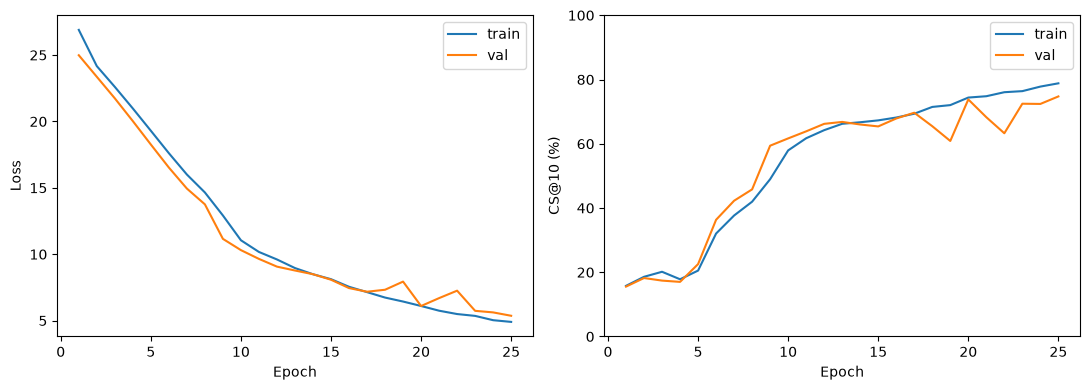

In [24]:
# 수정 금지

fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # 1×2 그림
for split in ['train', 'val']:  # train, val 두 가지에 대해
    axes[0].plot([row['epoch'] for row in history], [row[f'{split}_loss'] for row in history], label=split)  # Loss 곡선
    axes[1].plot([row['epoch'] for row in history], [row[f'{split}_cs10'] for row in history], label=split)  # CS@10 곡선
axes[0].set_ylabel('Loss')  # y축 이름
axes[1].set_ylabel('CS@10 (%)')  # y축 이름
axes[1].set_ylim(0, 100)  # y축 범위 0~100
for axis in axes:  # 두 칸 모두
    axis.set_xlabel('Epoch')  # x축 이름
    axis.legend()  # 범례
plt.tight_layout()  # 여백 자동 정리
plt.show()  # 그림 표시


## 제출

아래 파일들을 제출하세요.
- 완성한 노트북 `.ipynb`
- Best 체크포인트 `outputs/P1_2_<수험번호>.pth`
- 학습 기록 `outputs/P1_2_<수험번호>_history.csv`

파일명에는 첫 셀의 수험번호가 자동으로 들어갑니다. 따로 이름을 바꿀 필요가 없습니다.
- 실제로 실행하는데 사용된 체크포인트 결과만 제출하세요.
- 실제로 실행한 validation 결과를 노트북에 남기세요.



<details>
<summary>모델 코드 출처와 라이선스</summary>

모델 구현은 Microsoft TinyViT와 timm v1.0.22를 참고한 수정본입니다.

원본: Microsoft Cream/TinyViT, timm (Ross Wightman 및 기여자). Apache License 2.0.

```text
                                 Apache License
                           Version 2.0, January 2004
                        http://www.apache.org/licenses/

   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION

   1. Definitions.

      "License" shall mean the terms and conditions for use, reproduction,
      and distribution as defined by Sections 1 through 9 of this document.

      "Licensor" shall mean the copyright owner or entity authorized by
      the copyright owner that is granting the License.

      "Legal Entity" shall mean the union of the acting entity and all
      other entities that control, are controlled by, or are under common
      control with that entity. For the purposes of this definition,
      "control" means (i) the power, direct or indirect, to cause the
      direction or management of such entity, whether by contract or
      otherwise, or (ii) ownership of fifty percent (50%) or more of the
      outstanding shares, or (iii) beneficial ownership of such entity.

      "You" (or "Your") shall mean an individual or Legal Entity
      exercising permissions granted by this License.

      "Source" form shall mean the preferred form for making modifications,
      including but not limited to software source code, documentation
      source, and configuration files.

      "Object" form shall mean any form resulting from mechanical
      transformation or translation of a Source form, including but
      not limited to compiled object code, generated documentation,
      and conversions to other media types.

      "Work" shall mean the work of authorship, whether in Source or
      Object form, made available under the License, as indicated by a
      copyright notice that is included in or attached to the work
      (an example is provided in the Appendix below).

      "Derivative Works" shall mean any work, whether in Source or Object
      form, that is based on (or derived from) the Work and for which the
      editorial revisions, annotations, elaborations, or other modifications
      represent, as a whole, an original work of authorship. For the purposes
      of this License, Derivative Works shall not include works that remain
      separable from, or merely link (or bind by name) to the interfaces of,
      the Work and Derivative Works thereof.

      "Contribution" shall mean any work of authorship, including
      the original version of the Work and any modifications or additions
      to that Work or Derivative Works thereof, that is intentionally
      submitted to Licensor for inclusion in the Work by the copyright owner
      or by an individual or Legal Entity authorized to submit on behalf of
      the copyright owner. For the purposes of this definition, "submitted"
      means any form of electronic, verbal, or written communication sent
      to the Licensor or its representatives, including but not limited to
      communication on electronic mailing lists, source code control systems,
      and issue tracking systems that are managed by, or on behalf of, the
      Licensor for the purpose of discussing and improving the Work, but
      excluding communication that is conspicuously marked or otherwise
      designated in writing by the copyright owner as "Not a Contribution."

      "Contributor" shall mean Licensor and any individual or Legal Entity
      on behalf of whom a Contribution has been received by Licensor and
      subsequently incorporated within the Work.

   2. Grant of Copyright License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      copyright license to reproduce, prepare Derivative Works of,
      publicly display, publicly perform, sublicense, and distribute the
      Work and such Derivative Works in Source or Object form.

   3. Grant of Patent License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      (except as stated in this section) patent license to make, have made,
      use, offer to sell, sell, import, and otherwise transfer the Work,
      where such license applies only to those patent claims licensable
      by such Contributor that are necessarily infringed by their
      Contribution(s) alone or by combination of their Contribution(s)
      with the Work to which such Contribution(s) was submitted. If You
      institute patent litigation against any entity (including a
      cross-claim or counterclaim in a lawsuit) alleging that the Work
      or a Contribution incorporated within the Work constitutes direct
      or contributory patent infringement, then any patent licenses
      granted to You under this License for that Work shall terminate
      as of the date such litigation is filed.

   4. Redistribution. You may reproduce and distribute copies of the
      Work or Derivative Works thereof in any medium, with or without
      modifications, and in Source or Object form, provided that You
      meet the following conditions:

      (a) You must give any other recipients of the Work or
          Derivative Works a copy of this License; and

      (b) You must cause any modified files to carry prominent notices
          stating that You changed the files; and

      (c) You must retain, in the Source form of any Derivative Works
          that You distribute, all copyright, patent, trademark, and
          attribution notices from the Source form of the Work,
          excluding those notices that do not pertain to any part of
          the Derivative Works; and

      (d) If the Work includes a "NOTICE" text file as part of its
          distribution, then any Derivative Works that You distribute must
          include a readable copy of the attribution notices contained
          within such NOTICE file, excluding those notices that do not
          pertain to any part of the Derivative Works, in at least one
          of the following places: within a NOTICE text file distributed
          as part of the Derivative Works; within the Source form or
          documentation, if provided along with the Derivative Works; or,
          within a display generated by the Derivative Works, if and
          wherever such third-party notices normally appear. The contents
          of the NOTICE file are for informational purposes only and
          do not modify the License. You may add Your own attribution
          notices within Derivative Works that You distribute, alongside
          or as an addendum to the NOTICE text from the Work, provided
          that such additional attribution notices cannot be construed
          as modifying the License.

      You may add Your own copyright statement to Your modifications and
      may provide additional or different license terms and conditions
      for use, reproduction, or distribution of Your modifications, or
      for any such Derivative Works as a whole, provided Your use,
      reproduction, and distribution of the Work otherwise complies with
      the conditions stated in this License.

   5. Submission of Contributions. Unless You explicitly state otherwise,
      any Contribution intentionally submitted for inclusion in the Work
      by You to the Licensor shall be under the terms and conditions of
      this License, without any additional terms or conditions.
      Notwithstanding the above, nothing herein shall supersede or modify
      the terms of any separate license agreement you may have executed
      with Licensor regarding such Contributions.

   6. Trademarks. This License does not grant permission to use the trade
      names, trademarks, service marks, or product names of the Licensor,
      except as required for reasonable and customary use in describing the
      origin of the Work and reproducing the content of the NOTICE file.

   7. Disclaimer of Warranty. Unless required by applicable law or
      agreed to in writing, Licensor provides the Work (and each
      Contributor provides its Contributions) on an "AS IS" BASIS,
      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or
      implied, including, without limitation, any warranties or conditions
      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A
      PARTICULAR PURPOSE. You are solely responsible for determining the
      appropriateness of using or redistributing the Work and assume any
      risks associated with Your exercise of permissions under this License.

   8. Limitation of Liability. In no event and under no legal theory,
      whether in tort (including negligence), contract, or otherwise,
      unless required by applicable law (such as deliberate and grossly
      negligent acts) or agreed to in writing, shall any Contributor be
      liable to You for damages, including any direct, indirect, special,
      incidental, or consequential damages of any character arising as a
      result of this License or out of the use or inability to use the
      Work (including but not limited to damages for loss of goodwill,
      work stoppage, computer failure or malfunction, or any and all
      other commercial damages or losses), even if such Contributor
      has been advised of the possibility of such damages.

   9. Accepting Warranty or Additional Liability. While redistributing
      the Work or Derivative Works thereof, You may choose to offer,
      and charge a fee for, acceptance of support, warranty, indemnity,
      or other liability obligations and/or rights consistent with this
      License. However, in accepting such obligations, You may act only
      on Your own behalf and on Your sole responsibility, not on behalf
      of any other Contributor, and only if You agree to indemnify,
      defend, and hold each Contributor harmless for any liability
      incurred by, or claims asserted against, such Contributor by reason
      of your accepting any such warranty or additional liability.

   END OF TERMS AND CONDITIONS

   APPENDIX: How to apply the Apache License to your work.

      To apply the Apache License to your work, attach the following
      boilerplate notice, with the fields enclosed by brackets "{}"
      replaced with your own identifying information. (Don't include
      the brackets!)  The text should be enclosed in the appropriate
      comment syntax for the file format. We also recommend that a
      file or class name and description of purpose be included on the
      same "printed page" as the copyright notice for easier
      identification within third-party archives.

   Copyright 2019 Ross Wightman

   Licensed under the Apache License, Version 2.0 (the "License");
   you may not use this file except in compliance with the License.
   You may obtain a copy of the License at

       http://www.apache.org/licenses/LICENSE-2.0

   Unless required by applicable law or agreed to in writing, software
   distributed under the License is distributed on an "AS IS" BASIS,
   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
   See the License for the specific language governing permissions and
   limitations under the License.

```
